In [88]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.optimize import curve_fit
import h5py


In [66]:
hf = h5py.File('uwphys434/gammaray_lab4.h5', 'r')

In [67]:
hf.keys()

<KeysViewHDF5 ['data']>

In [68]:
data = np.array(hf.get('data'))

In [69]:
print(np.shape(data))
data[:,0]

(4, 25920001)


array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [70]:
hf.close()

# Problem

### 1. Examining data
The columns are seconds (gps time), solar phase (deg), earth longitude, particle counts.

A feature that stands out on the particle count distribution vs orbital coordinates chart is that the particle counts increase around the earth longitude $ \approx\ 320$ degrees and trail off around $ 360 $ degrees. This is independent of the solar phase value, and largely has to do with the position of the satellite over the Earth.

In [71]:

time_gps = data[0, :]
solar_phase = data[1, :]
earth_long = data[2, :]
particle_counts = data[3, :]

print("--- Data Summary---")
print(f"Total data points: {data.shape[1]:,}")
print(f"Time Range (GPS seconds): {time_gps.min()} to {time_gps.max()}")
print(f"Total Duration (days): {(time_gps.max() - time_gps.min()) / 86400:.2f}")
print(f"Solar Phase Range (deg): {solar_phase.min():.2f} to {solar_phase.max():.2f}")
print(f"Earth Longitude Range (deg): {earth_long.min():.2f} to {earth_long.max():.2f}")
print(f"Particle Counts - Min: {particle_counts.min()}, Max: {particle_counts.max()}, Mean: {particle_counts.mean():.2f}")



--- Data Summary---
Total data points: 25,920,001
Time Range (GPS seconds): 940680016.0 to 943272016.0
Total Duration (days): 30.00
Solar Phase Range (deg): 0.00 to 360.00
Earth Longitude Range (deg): 0.00 to 359.99
Particle Counts - Min: 0.0, Max: 30.0, Mean: 7.10


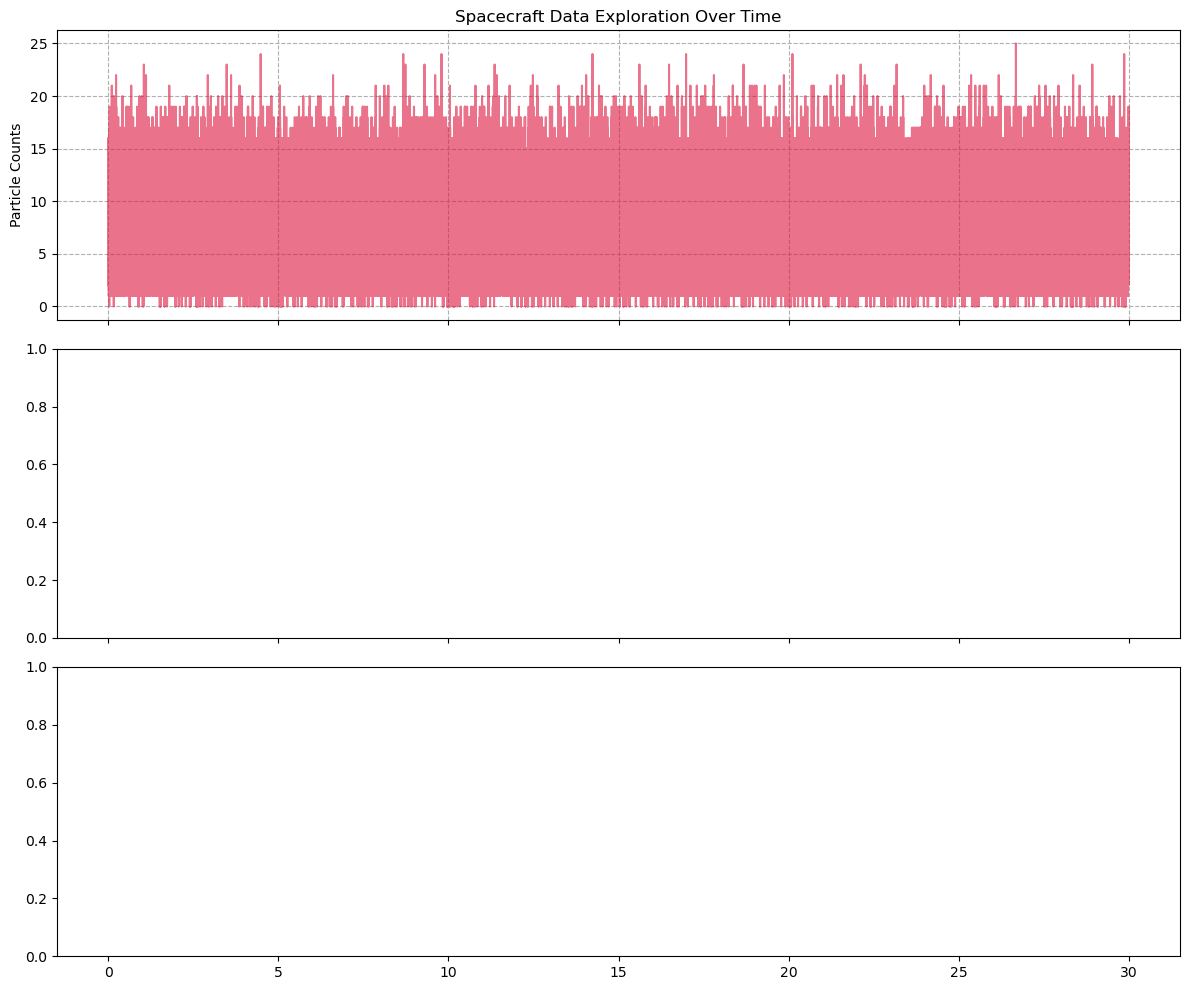

In [80]:
# Plotting every 100th point in the data
stride = 100
t_plot = time_gps[::stride]
solar_plot = solar_phase[::stride]
long_plot = earth_long[::stride]
counts_plot = particle_counts[::stride]

# Convert GPS time to relative hours or days from start for cleaner X-axes
time_days = (t_plot - time_gps[0]) / 86400

fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Particle Counts over Time
axs[0].plot(time_days, counts_plot, color='crimson', alpha=0.6, label='Particle Counts')
axs[0].set_ylabel('Particle Counts')
axs[0].set_title('Spacecraft Data Exploration Over Time')
axs[0].grid(True, linestyle='--')

#


#

plt.tight_layout()
plt.show()

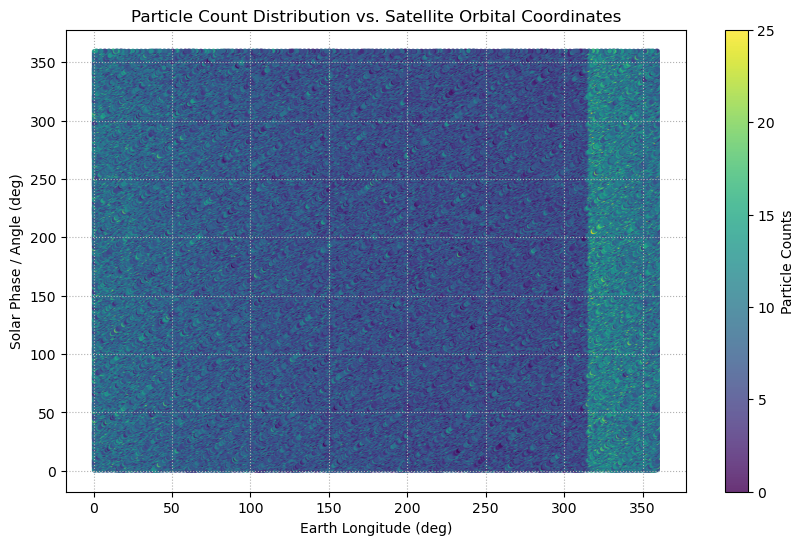

In [81]:
plt.figure(figsize=(10, 6))
# Using a scatter plot with a colormap to see "hotspots"
sc = plt.scatter(long_plot, solar_plot, c=counts_plot, cmap='viridis', s=5, alpha=0.8)
cbar = plt.colorbar(sc)
cbar.set_label('Particle Counts')

plt.title('Particle Count Distribution vs. Satellite Orbital Coordinates')
plt.xlabel('Earth Longitude (deg)')
plt.ylabel('Solar Phase / Angle (deg)')
plt.grid(True, linestyle=':')
plt.show()

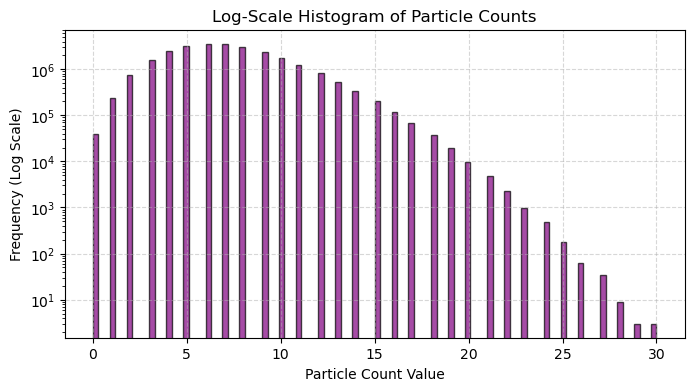

In [79]:
plt.figure(figsize=(8, 4))
plt.hist(particle_counts, bins=100, color='purple', log=True, edgecolor='black', alpha=0.7)
plt.title('Log-Scale Histogram of Particle Counts')
plt.xlabel('Particle Count Value')
plt.ylabel('Frequency (Log Scale)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2.



In [89]:

# Analysis: Bin data to inspect macro background changes

# Group into 1-hour bins to smooth out high-frequency noise
bin_size_sec = 3600 
total_bins = int((time_gps[-1] - time_gps[0]) / bin_size_sec)

bin_edges = np.linspace(time_gps[0], time_gps[-1], total_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
bin_centers_days = (bin_centers - time_gps[0]) / 86400.0

# Compute median counts per bin (medians are robust against brief GRB spikes)
binned_bg_mean = []
binned_bg_median = []

for i in range(total_bins):
    mask = (time_gps >= bin_edges[i]) & (time_gps < bin_edges[i+1])
    if np.sum(mask) > 0:
        binned_bg_median.append(np.median(particle_counts[mask]))
        binned_bg_mean.append(np.mean(particle_counts[mask]))
    else:
        binned_bg_median.append(np.nan)
        binned_bg_mean.append(np.nan)

binned_bg_median = np.array(binned_bg_median)
binned_bg_mean = np.array(binned_bg_mean)

# Print diagnostic insights
print("--- Background Characterization ---")
print(f"Global Particle Mean: {particle_counts.mean():.4f}")
print(f"Hourly Median Background Range: {np.nanmin(binned_bg_median)} to {np.nanmax(binned_bg_median)}")

--- Background Characterization ---
Global Particle Mean: 7.0973
Hourly Median Background Range: 6.0 to 7.0


### 3.


--- Model Parameters & Evaluation ---
Baseline (a0): 7.096
Long-term Drift (a1 per day): 0.00008
Orbital Modulation Amplitude: -0.091
Root Mean Squared Error (RMSE): 0.4981 counts
R² Score: 0.0165


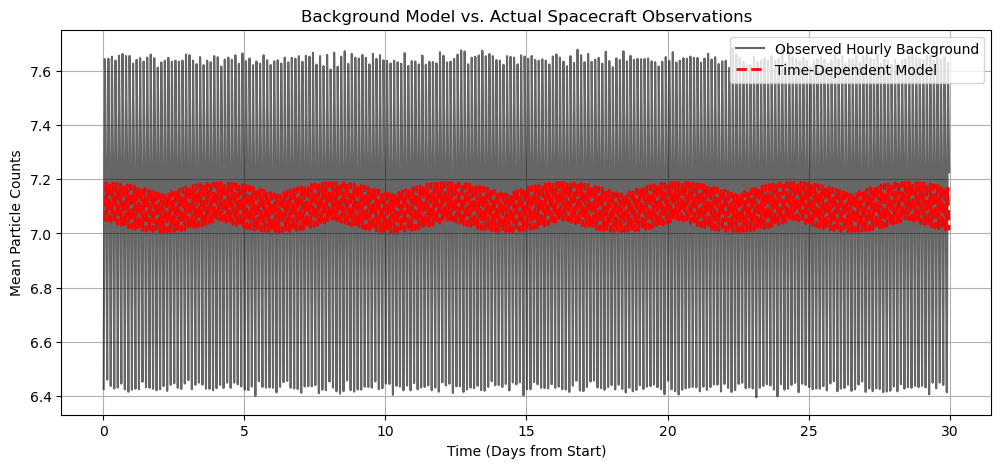

In [90]:

# Background model fitting

# Define a model function: Linear trend + Sinusoidal orbital variation
# (We estimate omega based on an assumed 90-minute / 0.0625-day low earth orbit)
def background_model(t, a0, a1, amp, omega, phase):
    return a0 + a1 * t + amp * np.sin(omega * t + phase)

# Filter out any NaNs from our binned tracking data
valid = ~np.isnan(binned_bg_mean)
t_fit = bin_centers_days[valid]
y_fit = binned_bg_mean[valid]

# Initial guesses: [intercept, slope, amplitude, frequency (rad/day), phase]
# 2*pi / 0.0625 days ~= 100 rad/day for a standard LEO orbit
initial_guess = [7.1, 0.0, 2.0, 100.0, 0.0]

popt, pcov = curve_fit(background_model, t_fit, y_fit, p0=initial_guess)
a0_fit, a1_fit, amp_fit, omega_fit, phase_fit = popt

# Generate model predictions across the whole timeline
model_bg_hourly = background_model(bin_centers_days, *popt)


# Evaluating model (Goodness of Fit)

residuals = y_fit - background_model(t_fit, *popt)
rmse = np.sqrt(np.mean(residuals**2))
r_squared = 1 - (np.sum(residuals**2) / np.sum((y_fit - np.mean(y_fit))**2))

print("\n--- Model Parameters & Evaluation ---")
print(f"Baseline (a0): {a0_fit:.3f}")
print(f"Long-term Drift (a1 per day): {a1_fit:.5f}")
print(f"Orbital Modulation Amplitude: {amp_fit:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} counts")
print(f"R² Score: {r_squared:.4f}")

# Plot Data vs Model Comparison
plt.figure(figsize=(12, 5))
plt.plot(bin_centers_days, y_fit, label='Observed Hourly Background', color='black', alpha=0.6)
plt.plot(bin_centers_days, model_bg_hourly, label='Time-Dependent Model', color='red', linestyle='--', linewidth=2)
plt.title('Background Model vs. Actual Spacecraft Observations')
plt.xlabel('Time (Days from Start)')
plt.ylabel('Mean Particle Counts')
plt.legend()
plt.grid(True)
plt.show()


### 4. 

Because there is a region where the background is much higher than other areas

In [91]:
from scipy.stats import poisson

# Evaluate background model at a quiet time (min background) vs active time (max background)
bg_min = background_model(bin_centers_days, *popt).min()
bg_max = background_model(bin_centers_days, *popt).max()

def get_poisson_5sigma_threshold(expected_bg):
    """Finds the integer count threshold required to meet a 5-sigma confidence level."""
    target_p_value = 2.87e-7
    # poisson.ppf calculates the quantile (inverse CDF)
    threshold = poisson.ppf(1 - target_p_value, expected_bg)
    return int(threshold)

thresh_at_min = get_poisson_5sigma_threshold(bg_min)
thresh_at_max = get_poisson_5sigma_threshold(bg_max)

print("\n--- 5-Sigma Discovery Sensitivities (for 100ms windows) ---")
print(f"At lowest background intensity ({bg_min:.2f} counts/100ms):")
print(f"   --> You need to see at least {thresh_at_min} particles in 100ms to claim a 5-sigma discovery.")
print(f"At highest background intensity ({bg_max:.2f} counts/100ms):")
print(f"   --> You need to see at least {thresh_at_max} particles in 100ms to claim a 5-sigma discovery.")



--- 5-Sigma Discovery Sensitivities (for 100ms windows) ---
At lowest background intensity (7.01 counts/100ms):
   --> You need to see at least 24 particles in 100ms to claim a 5-sigma discovery.
At highest background intensity (7.19 counts/100ms):
   --> You need to see at least 24 particles in 100ms to claim a 5-sigma discovery.


### 5. 

The variable background appears to be like the effect that the South Atlantic Anomaly has on satellites orbiting the Earth, where the inner van allen radiation belt comes down close to Earth and has charged particles that can hit the detector on the satellite. In the case of the south atlantic anomaly, the span is from -90 degrees to +40 degrees in longitude. Here, we can see the background increases the most around 320 degrees to about 50 degrees longitude or so. 
